# Structured-kernel learning curves, past the trained range: paper figure

Loads one `structured_krr_*.pkl` written by `run_structured_kernel_learning_curves.ipynb` (one pool, one
$T$) and draws the test error against $n$ for in-distribution and out-of-distribution side by side: the
eigenlearning theory as the line and the trained kernel as markers ($\pm 1$ standard deviation over
trials), in the style of `plot_eigenlearning_fixed_tasks.ipynb`.

The difference is the x-range. That notebook stops just past the last trained point; here the theory
runs on to `XMAX` ($10^{12}$ by default), because the structured kernel's OOD dip and rise happen at
$n \sim 10^6$--$10^8$, far beyond what KRR can train. The run stores the theory to $10^{18}$, so nothing
is recomputed. `ORACLES` and `FLOORS` add the Ridge / dMMSE levels and the $n\to\infty$ floors per
degree for reference.

## Colab setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys, os, getpass

# Token via Colab secrets (or a prompt) rather than a literal, so the notebook can be committed.
try:
    from google.colab import userdata
    GIT_TOKEN = userdata.get('GIT_TOKEN')
except Exception:
    GIT_TOKEN = getpass.getpass('GitHub PAT: ')
GIT_USER = "JoeyTurn"
GIT_REPO = "kernel_ICL"

!git clone https://{GIT_TOKEN}@github.com/{GIT_USER}/{GIT_REPO}.git

sys.path.insert(0, "/content/kernel_ICL")
sys.path.insert(0, "/content/kernel_ICL/expts/rf_scaling")

RESULTPATH = "/content/drive/MyDrive/results"
os.environ["RESULTPATH"] = RESULTPATH
os.makedirs(RESULTPATH, exist_ok=True)

!git clone https://github.com/dkarkada/expt-core.git

sys.path.insert(0, "/content/expt-core")
from misc import rcsetup
rcsetup()

Mounted at /content/drive
GitHub PAT: ··········
Cloning into 'kernel_ICL'...
remote: Enumerating objects: 1010, done.
remote: Counting objects: 100% (43/43), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 1010 (delta 20), reused 34 (delta 15), pack-reused 967 (from 1)
Receiving objects: 100% (1010/1010), 56.31 MiB | 27.65 MiB/s, done.
Resolving deltas: 100% (544/544), done.
Cloning into 'expt-core'...
remote: Enumerating objects: 58, done.
remote: Counting objects: 100% (58/58), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 58 (delta 28), reused 47 (delta 17), pack-reused 0 (from 0)
Receiving objects: 100% (58/58), 16.11 KiB | 402.00 KiB/s, done.
Resolving deltas: 100% (28/28), done.


In [ ]:
import os, sys, glob, pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import ticker

if os.path.exists("/content/kernel_ICL"):
    # Colab: re-add the paths in case the runtime was restarted after the setup cell
    for p in ("/content/kernel_ICL", "/content/kernel_ICL/expts/rf_scaling", "/content/expt-core"):
        if p not in sys.path:
            sys.path.insert(0, p)
    RESULTPATH = os.environ.get("RESULTPATH", "/content/drive/MyDrive/results")
else:
    ROOT = Path.cwd()
    while ROOT != ROOT.parent and not (ROOT / "kernels_can_icl" / "__init__.py").exists():
        ROOT = ROOT.parent
    sys.path.insert(0, str(ROOT))
    sys.path.insert(0, str(ROOT / "expts" / "rf_scaling"))
    sys.path.insert(0, str(ROOT.parent / "expt-core"))
    RESULTPATH = str(ROOT / "expts" / "rf_scaling" / "results")

try:
    from misc import rcsetup
    rcsetup()
except ImportError:                     # the same settings as expt-core's misc.rcsetup
    plt.rc("figure", dpi=120, facecolor=(1, 1, 1))
    plt.rc("font", family="stixgeneral", size=12)
    plt.rc("axes", facecolor=(1, .99, .95), titlesize=12)
    plt.rc("mathtext", fontset="cm")
    plt.rc("pdf", fonttype=42)
    plt.rc("ps", fonttype=42)
print("RESULTPATH:", RESULTPATH)

RESULTPATH: /content/drive/MyDrive/results


## Settings

In [ ]:
RUN         = None                    # None = the newest structured_krr_*.pkl; else a file name, a path,
                                      #   or any part of a name (e.g. "whiten")
LAYOUT      = "stack+learn"                  # "side" (ID | OOD) or "stack" (ID over OOD); add "+learn" for the
                                      #   mode-acquisition panel: "side+learn", "stack+learn"
SIDES       = ("ID", "OOD")           # the error panels, in order
XMAX        = 1e12                    # draw the theory out to this n
XMIN        = None                    # start the x-axis here (None = just below the first trained n);
                                      #   e.g. 30 drops the noisiest small-n points and widens the rest
ORACLES     = True                    # Ridge and dMMSE as dashed lines
FLOORS      = ()                      # data degrees whose n -> infinity floor to draw, e.g. (3, 9)
SHADE_BEYOND = False                  # lightly shade the n past the last trained point
BASE        = "xkcd:cerulean"         # the theory's colour; the markers are a lighter shade of it
FONTSIZE    = 16
FIGSIZE     = None                    # None = a size that suits the layout
YLIM        = (0.4, 1.2)
YLIM_OOD    = (0.4, 1.2)                    # e.g. (0.4, 1.9); default fits the theory and the reference lines --
                                      #   an error bar taller than that runs off the edge rather than
                                      #   squashing the whole curve (n=10 KRR is very noisy)
LEGEND_LOC  = "upper right"          # in the first error panel
CAPTION_LOC = "under title"           # the setting, in the last error panel: "under title" or a corner

# --- mode acquisition panel (needs a run that saved the learnabilities) ---
LEARN_DEGREES = None                  # which data degrees to draw (None = all of them). Only the
                                      #   power-weighted curve per degree is drawn, not the single modes
LEARN_NHALF   = True                  # dotted vertical where each degree reaches learnability 1/2
LEARN_LEGEND  = "inline"              # "inline" labels at each curve, "box" for a legend, or None

# --- acquisition phases, shaded across every panel ---
PHASES       = True                   # Phase 1 the pool mean, Phase 2 the in-context direction, Phase 3
                                      #   the higher-order terms
PHASE_EDGES  = (3e2, 8e5)             # n at the phase boundaries; k edges -> k+1 phases
PHASE_LABELS = ()#("Phase 1", "Phase 2", "Phase 3")
PHASE_COLORS = ("#7fb3d5", "#7dcea0", "#f0b27a")
PHASE_ALPHA  = 0.28
PHASE_DARKEN = 0.78
PHASE_SAT = 1.75
PHASE_EDGE_LW = 1.2

In [ ]:
RESULTS_DIR = os.path.join(RESULTPATH, "structured_kernel")


def find_run(run, folder):
    """A RUN setting -> a pickle path: None = newest, else an existing path, a file name in the folder,
    or the newest file whose name contains `run`."""
    for cand in (run, os.path.join(folder, run or "")):
        if run and os.path.isfile(cand):
            return cand
    paths = glob.glob(os.path.join(folder, "structured_krr_new_*.pkl"))
    if run:
        paths = [p for p in paths if run in os.path.basename(p)]
    if not paths:
        raise FileNotFoundError(f"no structured_krr_*.pkl{f' matching {run!r}' if run else ''} in {folder}")
    return max(paths, key=os.path.getmtime)


PATH = find_run(RUN, RESULTS_DIR)
with open(PATH, "rb") as f:
    D = pickle.load(f)
C = D["config"]
TAG = os.path.basename(PATH).removeprefix("structured_krr_").removesuffix(".pkl")
E = np.asarray(D["emp_ID"])
print(f"{os.path.basename(PATH)}")
print(f"    d={C['DIM']}  L={C['L_CFG'] - 1} pairs  eps^2={C['EPS2']:g}  T={C['T']}  width {C['WIDTH']:g}  "
      f"ridge {C['RIDGE']:g}  max degree {C['MAX_LEVEL'] + 1}" + ("  whitened x" if C.get("WHITEN_X") else ""))
print(f"    trained: n = {min(D['NS']):,} .. {max(D['NS']):,} ({len(D['NS'])} sizes, {E.shape[0]} trials);"
      f"  theory: n = {D['th_n'][0]:.0e} .. {D['th_n'][-1]:.0e}")

structured_krr_new_d5_L8_e0.1_T16_normal_s0_w3_r0.01_whiten.pkl
    d=5  L=7 pairs  eps^2=0.1  T=16  width 3  ridge 0.01  max degree 7  whitened x
    trained: n = 10 .. 50,000 (15 sizes, 20 trials);  theory: n = 1e+01 .. 1e+12


## Figure

In [ ]:
import matplotlib.colors as mcolors
from matplotlib import ticker


def lighten(color, amount=0.5):
    """Interpolate a colour toward white (amount > 0) or black (amount < 0)."""
    rgb = mcolors.to_rgb(mcolors.XKCD_COLORS.get(color, color))
    new = tuple(c + (1 - c) * amount for c in rgb) if amount >= 0 else tuple(c * (1 + amount) for c in rgb)
    return tuple(min(max(x, 0), 1) for x in new)


def emp_stats(D, side):
    """(n, mean, sd) of the trained kernel over trials; sd is the sample SD (never the standard error)."""
    ns = np.asarray(D["NS"], float)
    E = np.asarray(D[f"emp_{side}"], float)                # (trials, len(NS))
    return ns, E.mean(0), (E.std(0, ddof=1) if E.shape[0] > 1 else np.zeros(len(ns)))


def refs(D, side, oracles, floors):
    """[(label, y, style)] for the horizontal reference lines: Ridge, dMMSE, and the requested floors.
    A floor at data degree k is the stored cut k - 1 (context level); (ID, OOD) per cut."""
    out = []
    if oracles:
        out += [("Generalizing solution", D["oracles"][f"ridge_{side.lower()}"], dict(color="black", lw=1.5)),
                ("Memorizing solution", D["oracles"][f"dmmse_{side.lower()}"], dict(color="xkcd:crimson", ls="--", lw=1.5))]
    shades = np.linspace(0.65, 0.3, max(len(floors), 1))
    for k, g in zip(floors, shades):
        fl = D["floors"].get(k - 1)
        if fl is not None:
            out.append((rf"Floor, deg $\leq {k}$", fl[0 if side == "ID" else 1],
                        dict(color=str(g), ls=":", lw=1.4)))
    return out


def caption(C):
    top = f"Structured kernel, $T={C['T']}$" + (", whitened $x$" if C.get("WHITEN_X") else "")
    return top + "\n" + rf"$d={C['DIM']}$, $L={C['L_CFG'] - 1}$, $\epsilon^2={C['EPS2']:g}$"


def corner(ax, text, loc="upper right", fontsize=12):
    """Grey text in a corner of the axes; "under title" sits beneath an upper-right corner label."""
    if loc == "under title":
        x, ha, y, va = 0.98, "right", 0.82, "top"
    else:
        x, ha = (0.95, "right") if "right" in loc else (0.2, "left")
        y, va = (0.97, "top") if "upper" in loc else (0.03, "bottom")
    ax.text(x, y, text, ha=ha, va=va, transform=ax.transAxes, fontsize=fontsize, color="xkcd:black",
            linespacing=1.35)


def log_decades(ax, lo, hi):
    """Major ticks every 2 decades (3 past 12), labelled 10^k; minor ticks at every decade."""
    k0, k1 = int(np.ceil(np.log10(lo))), int(np.floor(np.log10(hi)))
    step = 2 if k1 - k0 <= 12 else 3
    ax.xaxis.set_major_locator(ticker.FixedLocator([10.0 ** k for k in range(k0 + (k0 % step), k1 + 1, step)]))
    ax.xaxis.set_major_formatter(ticker.LogFormatterMathtext())
    ax.xaxis.set_minor_locator(ticker.FixedLocator([10.0 ** k for k in range(k0, k1 + 1)]))
    ax.xaxis.set_minor_formatter(ticker.NullFormatter())


def phase_spans(edges, xlim):
    """[(lo, hi)] for each phase, clipped to the axis."""
    inner = [e for e in edges if xlim[0] < e < xlim[1]]
    bounds = [xlim[0]] + inner + [xlim[1]]
    return list(zip(bounds[:-1], bounds[1:]))


# def draw_phases(ax, spans, colors, alpha):
#     """Tint the background of each phase. Behind everything, including the grid."""
#     for (a, b), c in zip(spans, colors):
#         ax.axvspan(a, b, color=c, alpha=alpha, lw=0, zorder=-20)


# def label_phases(ax, spans, labels, fontsize):
#     """Phase names centred in log n, in the margin just above the panel -- inside it they would run into
#     the corner label. Skipped where a phase is too narrow to read."""
#     for (a, b), lab in zip(spans, labels):
#         if np.log10(b / a) > 0.4:
#             ax.text(np.sqrt(a * b), 1.015, lab, transform=ax.get_xaxis_transform(), ha="center",
#                     va="bottom", fontsize=fontsize - 5, color="xkcd:dark gray")

def phase_inks(colors, alpha=0.28, darken=0.78, sat=1.75):
    """(wash, ink) per phase, built as the phase diagram builds them: the ink is the source colour with
    its saturation multiplied and its value cut; the wash -- the panel fill -- is that ink over white."""
    import colorsys
    wash, ink = [], []
    for c in colors:
        h, sat0, val = colorsys.rgb_to_hsv(*mcolors.to_rgb(c))
        k = colorsys.hsv_to_rgb(h, min(1.0, sat0 * sat), val * darken)
        ink.append(k)
        wash.append(tuple(1 - alpha + alpha * ch for ch in k))
    return wash, ink


def draw_phases(ax, spans, wash, ink=None, edge_lw=1.2):
    """Fill each phase with its wash, behind everything, and rule the boundaries in the ink."""
    for i, ((a, b), w) in enumerate(zip(spans, wash)):
        ax.axvspan(a, b, color=w, lw=0, zorder=-20)
        if i and ink is not None and edge_lw:
            ax.axvline(a, color=ink[i], lw=edge_lw, alpha=0.85, zorder=-19)


def label_phases(ax, spans, labels, fontsize, ink=None):
    """Phase names centred in log n, in the margin just above the panel, each in its phase's ink."""
    for i, ((a, b), lab) in enumerate(zip(spans, labels or ())):
        if np.log10(b / a) > 0.4:
            ax.text(np.sqrt(a * b), 1.015, lab, transform=ax.get_xaxis_transform(), ha="center",
                    va="bottom", fontsize=fontsize - 5,
                    color=(ink[i] if ink is not None else "xkcd:dark gray"))


def learn_panel(ax, D, th_n, keep, degrees=None, nhalf=True, legend="inline", fontsize=16):
    """Mode acquisition: one REPRESENTATIVE mode per data degree -- the one carrying the most target
    power -- so each curve is a single eigenfunction g_i rather than a power-weighted block. Needs a run
    that saved the per-mode arrays (learn_L, learn_power, learn_n_half, level); older pickles fall back
    to the per-degree curves."""
    lev = np.asarray(D.get("level", []), float)
    Lm = np.asarray(D.get("learn_L", []), float)
    use_modes = lev.size > 0 and Lm.size > 0
    if use_modes:
        deg = (lev + 1).astype(int)
        pw, nh_all = np.asarray(D["learn_power"], float), np.asarray(D["learn_n_half"], float)
        all_deg = sorted(set(deg.tolist()))
        rep = {p: int(np.flatnonzero(deg == p)[np.argmax(pw[deg == p])]) for p in all_deg}
    else:
        dl = D.get("learn_deg_L") or {}
        all_deg, half = sorted(dl), (D.get("learn_deg_n_half") or {})
    shown = all_deg if degrees is None else [k for k in all_deg if k in degrees]
    cols = {p: plt.cm.tab10(i) for i, p in enumerate(all_deg)}
    cols[3], cols[5] = cols[5], cols[3]
    cols[7] = cols[5]
    for p in shown:
        if use_modes:
            k = rep[p]
            curve, nh = Lm[:, k], float(nh_all[k])
        else:
            curve, nh = np.asarray(dl[p], float), float(half.get(p, np.nan))
        ax.plot(th_n[keep], curve[keep], color=cols[p], lw=2.2, label=f"degree {p}", zorder=4)
        # if nhalf and np.isfinite(nh):
        #     ax.axvline(nh, color=cols[p], ls=":", lw=1.0, zorder=-6)
        if legend == "inline" and np.isfinite(nh):
            x0, x1 = ax.get_xlim()
            if p == 1:
                ax.text(min(max(nh, x0 * 1.3), x1 / 1.3)+8, 0.46, rf"$g_0$", color=cols[p], ha="center",
                    va="bottom", fontsize=fontsize - 5, zorder=5,)
                    # bbox=dict(fc=(1, 1, 1, 0.65), ec="none", pad=1.0))
            elif p == 3:
                ax.text(min(max(nh, x0 * 1.3), x1 / 1.3)+3000, 0.46, rf"$g_1$", color=cols[p], ha="center",
                    va="bottom", fontsize=fontsize - 5, zorder=5,)
                    # bbox=dict(fc=(1, 1, 1, 0.65), ec="none", pad=1.0))
            elif p == 5:
                ax.text(min(max(nh, x0 * 1.3), x1 / 1.3)+2e7, 0.46, rf"$g_2$", color=cols[p], ha="center",
                    va="bottom", fontsize=fontsize - 5, zorder=5,)
                    # bbox=dict(fc=(1, 1, 1, 0.65), ec="none", pad=1.0))
            else:
                ax.text(min(max(nh, x0 * 1.3), x1 / 1.3)+2e11, 0.46, rf"$g_3$", color=cols[p], ha="center",
                    va="bottom", fontsize=fontsize - 5, zorder=5,)
                    #bbox=dict(fc=(1, 1, 1, 0.65), ec="none", pad=1.0))
    # ax.axhline(0.5, color="k", lw=0.8, ls=":", alpha=0.6, zorder=-6)
    ax.set_ylim(-0.02, 1.02)
    ax.set_ylabel(r"$\frac{\mathbb{E}[\langle g_i, \hat{f}_\text{ker} \rangle]}{\langle g_i, f_\mathrm{mem} \rangle}$", fontsize=fontsize)
    if legend == "box":
        ax.legend(fontsize=fontsize - 5, framealpha=0.8, handlelength=1.2, labelspacing=0.15,
                  borderpad=0.25, handletextpad=0.4, borderaxespad=0.15, loc="upper left")


def plot_extended(D, sides=("ID", "OOD"), xmax=1e12, base="xkcd:cerulean", oracles=True, floors=(),
                  shade=False, ylim=None, ylim_ood=None, figsize=None, fontsize=16, legend_loc="center right",
                  caption_loc="under title", xmin=None, layout="side", learn_degrees=None,
                  learn_nhalf=True, learn_legend="inline", learn_size=0.5, phases=True,
                  phase_edges=(3e2, 8e5),
                #   learn_nhalf=True, learn_legend="inline", phases=True, phase_edges=(3e2, 8e5),
                  phase_labels=("Phase 1", "Phase 2", "Phase 3"),
                  phase_colors=("#7fb3d5", "#7dcea0", "#f0b27a"), phase_alpha=0.15):
    """The figure: one error panel per side, plus the mode-acquisition panel with "+learn", laid out
    side by side ("side") or stacked on a shared n axis ("stack"). The error panels share their y-axis.

    The automatic y-limits fit the theory curve and the reference lines only. Fitting the markers' error
    bars too lets the smallest n decide the whole axis: at n=10 the trial-to-trial SD is ~1, which squashed
    everything after it into the bottom quarter. Bars that reach past the limits run off the edge."""
    col = mcolors.to_rgb(mcolors.XKCD_COLORS.get(base, base))
    th_n = np.asarray(D["th_n"], float)
    ns = np.asarray(D["NS"], float)
    xlo = xmin if xmin else min(ns.min(), th_n.min()) / 1.15
    keep = (th_n >= xlo) & (th_n <= xmax * 1.0001)
    xlim = (xlo, xmax * 1.6)
    stacked = layout.startswith("stack")
    learn_on = layout.endswith("learn")
    if learn_on and not D.get("learn_deg_L"):
        print("this run saved no learnabilities (learn_deg_L) -- drawing the error panels only")
        learn_on = False

    # y-limits from the theory and the reference lines inside the x-range, shared by the error panels
    ys = []
    for side in sides:
        ys += list(np.asarray(D[f"th_{side}"], float)[keep])
        ys += [y for _, y, _ in refs(D, side, oracles, floors)]
    lo, hi = min(ys), max(ys)
    ylim = ylim or (lo - 0.07 * (hi - lo), hi + 0.07 * (hi - lo))
    ylim_ood = ylim_ood or (lo - 0.07 * (hi - lo), hi + 0.07 * (hi - lo))

    n_err = len(sides)
    n_ax = n_err + int(learn_on)
    ratios = [1.0] * n_err + ([learn_size] if learn_on else [])
    span = n_err + (learn_size if learn_on else 0.0)      # panel sizes in error-panel units
    if figsize is None: #4.8, 1.5 #7.8, 1.5 * n_ax + 0.6
        figsize = (5.0, 1.7 * span + 0.6) if stacked else (4.3 * span + 0.2, 3.0)
    fig, axs = plt.subplots(*((n_ax, 1) if stacked else (1, n_ax)), figsize=figsize, squeeze=False,
                            constrained_layout=True, sharex=stacked,
                            gridspec_kw=dict(hspace=0.08, height_ratios=ratios) if stacked
                            else dict(wspace=0.06, width_ratios=ratios))
    axs = axs[:, 0] if stacked else axs[0]
    for ax in axs[1:n_err]:                    # the error panels share one y scale
        ax.sharey(axs[0])
        if not stacked:
            ax.tick_params(labelleft=False)
    # spans = phase_spans(phase_edges, xlim) if phases else []
    spans = phase_spans(phase_edges, xlim) if phases else []
    wash, ink = phase_inks(phase_colors, phase_alpha, PHASE_DARKEN, PHASE_SAT)

    for i, side in enumerate(sides):
        ax = axs[i]
        draw_phases(ax, spans, wash, ink, PHASE_EDGE_LW)
        # draw_phases(ax, spans, phase_colors, phase_alpha)
        if shade:
            ax.axvspan(ns.max() * 1.15, xlim[1], color="0.5", alpha=0.07, lw=0, zorder=-10)
        for lab, y, st in refs(D, side, oracles, floors):
            ax.axhline(y, label=lab, zorder=-5, **st)
        n, m, sd = emp_stats(D, side)
        inx = n >= xlo                     # points left of XMIN are dropped, not squeezed against the axis
        n, m, sd = n[inx], m[inx], sd[inx]
        # trained kernel: markers only, lighter, behind the theory line
        ax.errorbar(n, m, yerr=sd, color=lighten(col, 0.45), ls="none", marker="o", ms=4.5,
                    elinewidth=1.2, capsize=0, zorder=-4, label="Kernel regression")
        ax.plot(th_n[keep], np.asarray(D[f"th_{side}"], float)[keep], color=col, lw=2, label="Theory")
        # corner(ax, "Pretrain Distribution" if side == "ID" else "Prior Distribution", fontsize=fontsize-1, loc="upper left")
        if stacked or i == 0:
            if side == "ID":
                ax.set_ylabel(f"Train Tasks\n Test MSE", fontsize=fontsize)
            elif side == "OOD":
                ax.set_ylabel(f"Novel Tasks\n Test MSE", fontsize=fontsize)
    axs[0].set_ylim(*ylim)
    axs[1].set_ylim(*ylim_ood)

    if learn_on:
        draw_phases(axs[-1], spans, wash, ink, PHASE_EDGE_LW)
        # draw_phases(axs[-1], spans, phase_colors, phase_alpha)
        axs[-1].set_xscale("log")
        axs[-1].set_xlim(*xlim)
        learn_panel(axs[-1], D, th_n, keep, learn_degrees, learn_nhalf, learn_legend, fontsize)

    for i, ax in enumerate(axs):
        ax.set_xscale("log")
        ax.set_xlim(*xlim)
        log_decades(ax, *xlim)
        ax.tick_params(labelsize=fontsize - 2)
        if not stacked or i == n_ax - 1:
            ax.set_xlabel("$n$ training samples", fontsize=fontsize, labelpad=0)
    if phases:
        label_phases(axs[0], spans, phase_labels, fontsize, ink)
        # label_phases(axs[0], spans, phase_labels, fontsize)

    h, l = axs[0].get_legend_handles_labels()
    order = [l.index(x) for x in ("Theory", "Kernel regression") if x in l] + \
            [i for i, x in enumerate(l) if x not in ("Theory", "Kernel regression")]
    axs[0].legend([h[i] for i in order], [l[i] for i in order], fontsize=fontsize - 7, framealpha=0.8,
                  handlelength=1.4, labelspacing=0.15, borderpad=0.25, handletextpad=0.4,
                  borderaxespad=0.15, loc=legend_loc)
    # corner(axs[n_err - 1], caption(D["config"]), loc=caption_loc, fontsize=fontsize - 3)
    # plt.tight_layout()
    return fig, axs

saved /content/drive/MyDrive/results/structured_kernel/figs/nl_structured_curves_stack_learn_to1e12_new_d5_L8_e0.1_T16_normal_s0_w3_r0.01_whiten.{pdf,png}


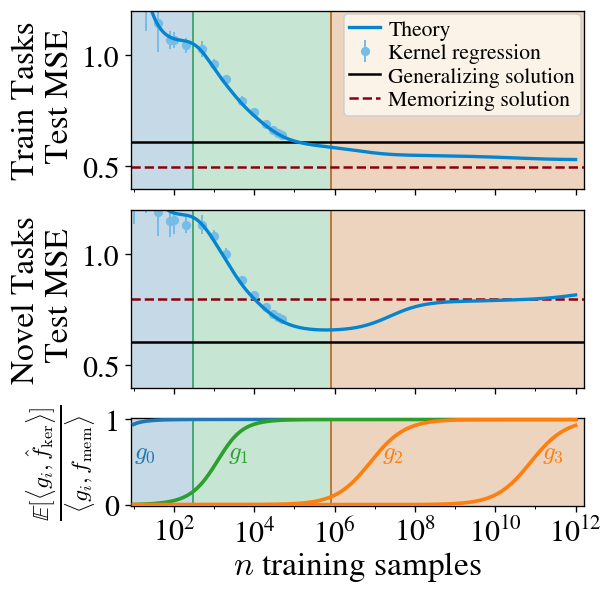

In [ ]:
FIGDIR = os.path.join(RESULTS_DIR, "figs")
os.makedirs(FIGDIR, exist_ok=True)
fig, axs = plot_extended(D, SIDES, XMAX, BASE, ORACLES, FLOORS, SHADE_BEYOND, YLIM, YLIM_OOD, FIGSIZE, FONTSIZE+4,
                         LEGEND_LOC, CAPTION_LOC, xmin=XMIN, layout=LAYOUT, learn_degrees=LEARN_DEGREES,
                         learn_nhalf=LEARN_NHALF, learn_legend=LEARN_LEGEND, phases=PHASES,
                         phase_edges=PHASE_EDGES, phase_labels=(), phase_colors=PHASE_COLORS,
                         phase_alpha=PHASE_ALPHA)
stem = os.path.join(FIGDIR, f"nl_structured_curves_{LAYOUT.replace('+', '_')}_"
                    f"to{XMAX:.0e}".replace("+", "") + f"_{TAG}")
fig.savefig(stem + ".pdf", bbox_inches="tight")
fig.savefig(stem + ".png", dpi=200, bbox_inches="tight")
print("saved", stem + ".{pdf,png}")
plt.show()

saved /content/drive/MyDrive/results/structured_kernel/figs/nl_structured_curves_stack_learn_to1e12_new_d5_L8_e0.1_T16_normal_s0_w3_r0.01_whiten.{pdf,png}


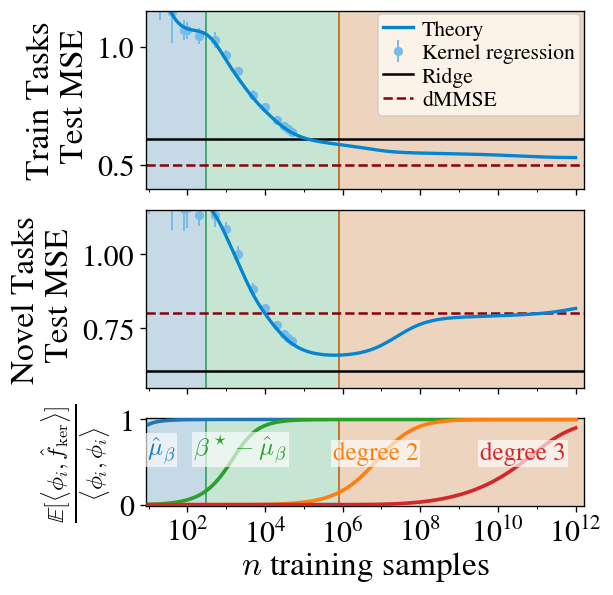

In [ ]:
FIGDIR = os.path.join(RESULTS_DIR, "figs")
os.makedirs(FIGDIR, exist_ok=True)
fig, axs = plot_extended(D, SIDES, XMAX, BASE, ORACLES, FLOORS, SHADE_BEYOND, YLIM, YLIM_OOD, FIGSIZE, FONTSIZE+4,
                         LEGEND_LOC, CAPTION_LOC, xmin=XMIN, layout=LAYOUT, learn_degrees=LEARN_DEGREES,
                         learn_nhalf=LEARN_NHALF, learn_legend=LEARN_LEGEND, phases=PHASES,
                         phase_edges=PHASE_EDGES, phase_labels=(), phase_colors=PHASE_COLORS,
                         phase_alpha=PHASE_ALPHA)
stem = os.path.join(FIGDIR, f"nl_structured_curves_{LAYOUT.replace('+', '_')}_"
                    f"to{XMAX:.0e}".replace("+", "") + f"_{TAG}")
fig.savefig(stem + ".pdf", bbox_inches="tight")
fig.savefig(stem + ".png", dpi=200, bbox_inches="tight")
print("saved", stem + ".{pdf,png}")
plt.show()